ANALISIS Y MODELADO PROYECTO P. 

In [2]:
#Comenzaremos pasando nuestros datos a un DataFrame de pandas
import pandas as pd
df = pd.read_csv('C:\\Users\\yetla\\Downloads\\BasesUnidas.csv')
df.head(6)


,Fecha_extraccion,Hora_extraccion,Origen,Destino,Fecha_salida,Hora_salida,Precio Sin TUA,Aerolinea,kilometros,Disponibilidad,Ruta,Aerolinea.1,Dias_anticipados,Hora_vuelo
0,"viernes, 10 de octubre de 2025",00:06:29,Ciudad de México (Mex),Tuxtla Gutiérrez (TGZ),"sábado, 20 de diciembre de 2025",20:00:00,3568.0,VivaAerobus,703 km,Disponible,MEX-TGZ,1.0,71.0,8.0
1,"viernes, 10 de octubre de 2025",00:06:44,Ciudad de México (Mex),Chihuahua (CUU),"sábado, 20 de diciembre de 2025",13:15:00,2182.0,VivaAerobus,1237 km,Disponible,MEX-CUU,1.0,71.0,1.5
2,"viernes, 10 de octubre de 2025",00:06:59,Ciudad de México (Mex),Veracruz (VER),"sábado, 20 de diciembre de 2025",16:15:00,2523.0,VivaAerobus,304 km,Disponible,MEX-VER,1.0,71.0,4.5
3,"viernes, 10 de octubre de 2025",00:07:15,Ciudad de México (Mex),Guadalajara (GDL),"sábado, 20 de diciembre de 2025",06:00:00,1219.0,VivaAerobus,454 km,Disponible,MEX-GDL,1.0,71.0,6.0
4,"viernes, 10 de octubre de 2025",01:07:30,Ciudad de México (Mex),Tuxtla Gutiérrez (TGZ),"sábado, 20 de diciembre de 2025",20:00:00,3568.0,VivaAerobus,703 km,Disponible,MEX-TGZ,1.0,71.0,8.0
5,"viernes, 10 de octubre de 2025",01:07:45,Ciudad de México (Mex),Chihuahua (CUU),"sábado, 20 de diciembre de 2025",13:15:00,2182.0,VivaAerobus,1237 km,Disponible,MEX-CUU,1.0,71.0,1.5


In [46]:
#Checaremos las columnas y tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2895 entries, 0 to 2894
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Fecha_extraccion  2891 non-null   object 
 1   Hora_extraccion   2891 non-null   object 
 2   Origen            2891 non-null   object 
 3   Destino           2891 non-null   object 
 4   Fecha_salida      2891 non-null   object 
 5   Hora_salida       2891 non-null   object 
 6   Precio Sin TUA    2891 non-null   float64
 7   Aerolinea         2891 non-null   object 
 8   kilometros        2891 non-null   object 
 9   Disponibilidad    2891 non-null   object 
 10  Ruta              2891 non-null   object 
 11  Aerolinea.1       2891 non-null   float64
 12  Dias_anticipados  2887 non-null   float64
 13  Hora_vuelo        2892 non-null   float64
dtypes: float64(4), object(10)
memory usage: 316.8+ KB


In [47]:
#Ahora verificaremos si hay valores nulos en el DataFrame 
df.isnull().sum()

Fecha_extraccion    4
Hora_extraccion     4
Origen              4
Destino             4
Fecha_salida        4
Hora_salida         4
Precio Sin TUA      4
Aerolinea           4
kilometros          4
Disponibilidad      4
Ruta                4
Aerolinea.1         4
Dias_anticipados    8
Hora_vuelo          3
dtype: int64

In [3]:
#En caso de hayan datos nulos los eliminaremos
df = df.dropna()
df.isnull().sum()

Fecha_extraccion    0
Hora_extraccion     0
Origen              0
Destino             0
Fecha_salida        0
Hora_salida         0
Precio Sin TUA      0
Aerolinea           0
kilometros          0
Disponibilidad      0
Ruta                0
Aerolinea.1         0
Dias_anticipados    0
Hora_vuelo          0
dtype: int64

In [4]:
#Cambiaremos el nombre de la columna Aerolinea.1
df = df.rename(columns={'Aerolinea.1':'Aerolinea'})

In [5]:
#Ahora convertiremos la columna 'Fecha_extraccion' a tipo datetime
import locale
locale.setlocale(locale.LC_TIME, "es_MX")  # O "es_MX" en Windows

df['Fecha_extraccion'] = pd.to_datetime(df['Fecha_extraccion'], format='%A, %d de %B de %Y')
# Ahora Fecha_salida
df['Fecha_salida'] = pd.to_datetime(df['Fecha_salida'], format='%A, %d de %B de %Y')
#Y la aerolinea a tipo categoria
df['Aerolinea'] = df['Aerolinea'].astype('category')
# Convertir Hora_extraccion a float
df['Hora_extraccion'] = pd.to_datetime(df['Hora_extraccion'], format="%H:%M:%S").dt.hour + \
                        pd.to_datetime(df['Hora_extraccion'], format="%H:%M:%S").dt.minute / 60

# Convertir Hora_salida a float
df['Hora_salida'] = pd.to_datetime(df['Hora_salida'], format="%H:%M:%S").dt.hour + \
                    pd.to_datetime(df['Hora_salida'], format="%H:%M:%S").dt.minute / 60
                    
#Por ultimo cambiamos la columna kilometros a tipo numérico
df['kilometros'] = df['kilometros'].str.replace('km','',regex=False)\
                                   .str.replace(' ','',regex=False)\
                                   .str.replace(',','',regex=False)\
                                   .astype(float)

df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 2887 entries, 0 to 2890
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Fecha_extraccion  2887 non-null   datetime64[ns]
 1   Hora_extraccion   2887 non-null   float64       
 2   Origen            2887 non-null   object        
 3   Destino           2887 non-null   object        
 4   Fecha_salida      2887 non-null   datetime64[ns]
 5   Hora_salida       2887 non-null   float64       
 6   Precio Sin TUA    2887 non-null   float64       
 7   Aerolinea         2887 non-null   category      
 8   kilometros        2887 non-null   float64       
 9   Disponibilidad    2887 non-null   object        
 10  Ruta              2887 non-null   object        
 11  Aerolinea         2887 non-null   category      
 12  Dias_anticipados  2887 non-null   float64       
 13  Hora_vuelo        2887 non-null   float64       
dtypes: category(2), datetime64[ns

In [6]:
#Verificamos si hay columnas duplicadas
df.columns[df.columns.duplicated()]


Index(['Aerolinea'], dtype='object')

In [7]:
#Eliminamos columnas duplicadas si es que existen
df = df.loc[:, ~df.columns.duplicated()]


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2887 entries, 0 to 2890
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Fecha_extraccion  2887 non-null   datetime64[ns]
 1   Hora_extraccion   2887 non-null   float64       
 2   Origen            2887 non-null   object        
 3   Destino           2887 non-null   object        
 4   Fecha_salida      2887 non-null   datetime64[ns]
 5   Hora_salida       2887 non-null   float64       
 6   Precio Sin TUA    2887 non-null   float64       
 7   Aerolinea         2887 non-null   category      
 8   kilometros        2887 non-null   float64       
 9   Disponibilidad    2887 non-null   object        
 10  Ruta              2887 non-null   object        
 11  Dias_anticipados  2887 non-null   float64       
 12  Hora_vuelo        2887 non-null   float64       
dtypes: category(1), datetime64[ns](2), float64(6), object(4)
memory usage: 296.2+ KB


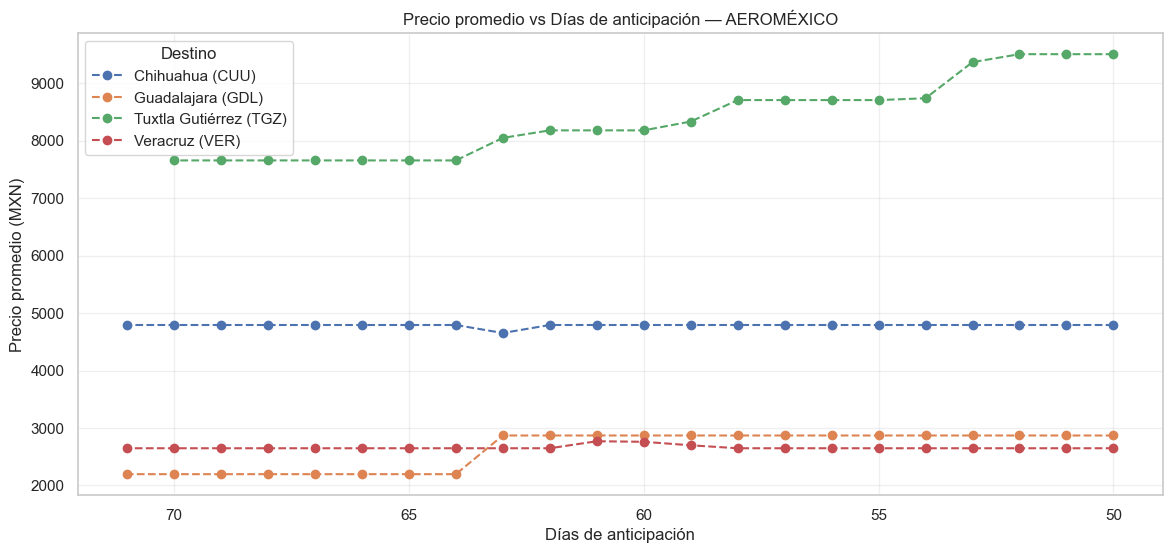

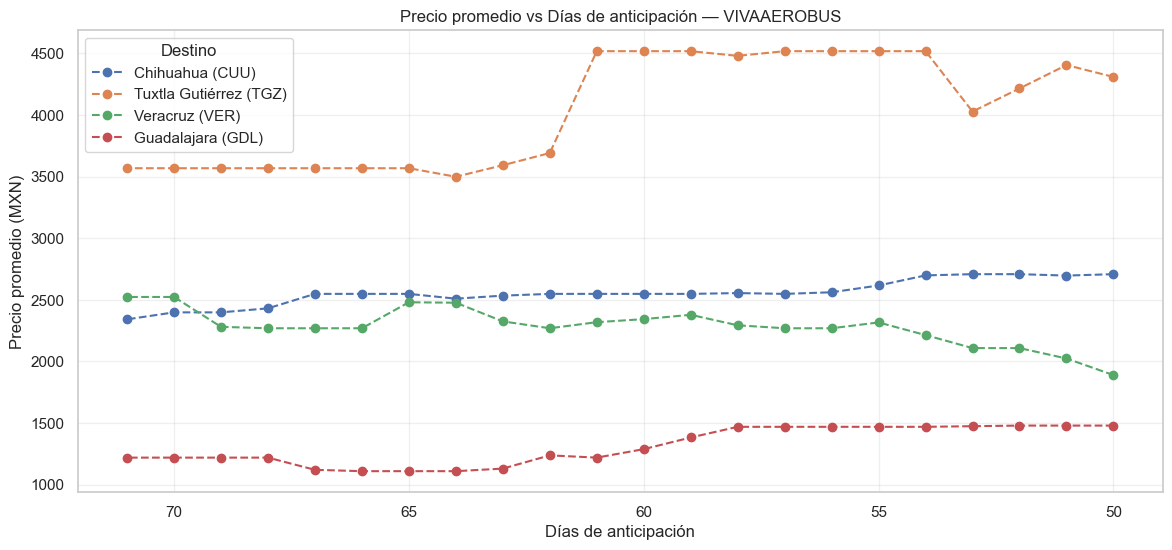

In [33]:
#Ahora para analizar los datos crearemos visualizaciones
#Graficaremos Precio por vuelo VS Días de anticipación de ambas aerolíneas
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# Aseguramos que los nombres coincidan exactamente con tu DataFrame:
#   "Aeromexico"
#   "VivaAerobus"
aerolineas = ["Aeroméxico", "VivaAerobus"]

for aer in aerolineas:
    df_aer = df[df['Aerolinea'] == aer]

    # Agrupar por destino y días de anticipación
    df_group = (
        df_aer.groupby(['Destino', 'Dias_anticipados'])['Precio Sin TUA']
              .mean()
              .reset_index()
              .sort_values('Dias_anticipados')
    )

    # Crear figura individual por aerolínea
    plt.figure(figsize=(14,6))

    destinos = df_group['Destino'].unique()

    # Una línea por destino
    for dest in destinos:
        data_dest = df_group[df_group['Destino'] == dest]
        plt.plot(
            data_dest['Dias_anticipados'],
            data_dest['Precio Sin TUA'],
            marker='o',
            linestyle='--',
            label=dest
        )

    plt.title(f"Precio promedio vs Días de anticipación — {aer.upper()}")
    plt.xlabel("Días de anticipación")
    plt.ylabel("Precio promedio (MXN)")
    plt.legend(title="Destino")
    
    # Invertimos eje X para que se vea igual que tu ejemplo (70 → 50)
    plt.gca().invert_xaxis()
    
    plt.grid(alpha=0.3)
    plt.show()



C:\Users\yetla\AppData\Local\Temp\ipykernel_107420\2049261919.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['Destino', 'Aerolinea'])['Precio Sin TUA']


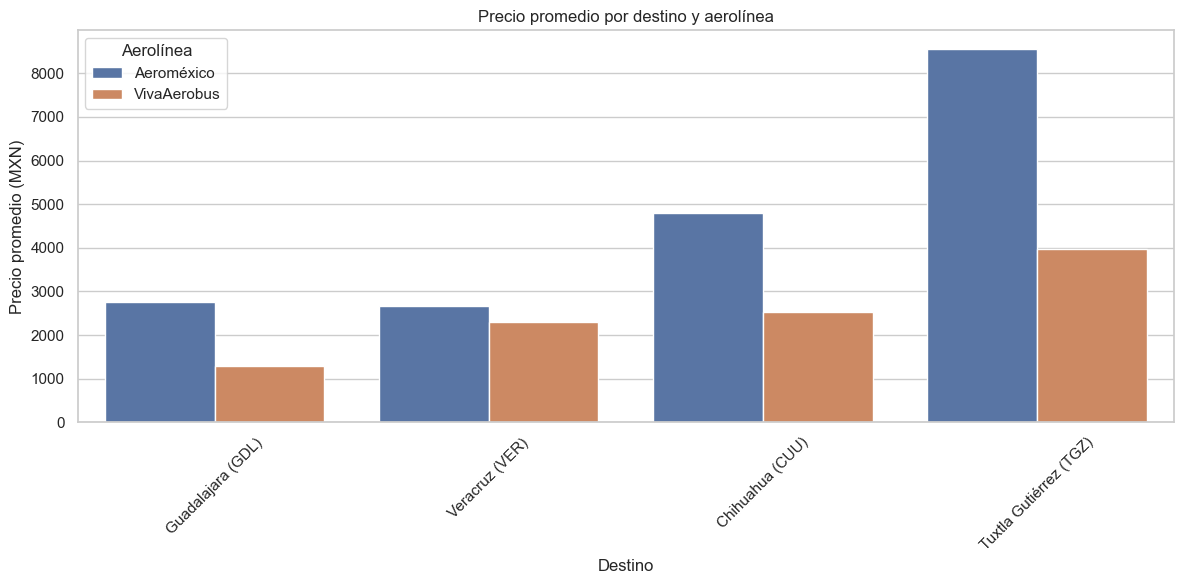

In [34]:
#Grafica 2. Precio promedio por destino y aerolínea
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# Agrupar por destino y aerolínea
df_bar = (
    df.groupby(['Destino', 'Aerolinea'])['Precio Sin TUA']
      .mean()
      .reset_index()
      .sort_values('Precio Sin TUA')
)

plt.figure(figsize=(12,6))

# Gráfica de barras agrupadas
sns.barplot(
    data=df_bar,
    x='Destino',
    y='Precio Sin TUA',
    hue='Aerolinea'
)

plt.title("Precio promedio por destino y aerolínea")
plt.xlabel("Destino")
plt.ylabel("Precio promedio (MXN)")
plt.xticks(rotation=45)
plt.legend(title="Aerolínea")
plt.tight_layout()
plt.show()



MODELO 

Dado el comportammiento de los datos, evidentemente un modelo de regresio lineal simple en este caso no será de utilidad por lo tanto aplicaremos 2 modelos: XGBoost o Random Forest, y de ahí veremos cuál es el más conveniente. 

In [8]:
#Pasaremos al modelado, dado que tanto XGBoost como Random Forest necesitan que los datos esten en categorías numéricas
# Entonces convertiremos las variables  destino y  ruta  a variables numéricas usando One-Hot Encoding 
df['Destino'] = df['Destino'].astype('category')
df['Disponibilidad'] = df['Disponibilidad'].astype('category')
df['Ruta'] = df['Ruta'].astype('category')
df = pd.get_dummies(df, columns=['Destino', 'Aerolinea', 'Disponibilidad', 'Ruta'], drop_first=False)

In [36]:
df.columns

Index(['Fecha_extraccion', 'Hora_extraccion', 'Origen', 'Fecha_salida',
       'Hora_salida', 'Precio Sin TUA', 'kilometros', 'Dias_anticipados',
       'Hora_vuelo ', 'Destino_Chihuahua (CUU)', 'Destino_Guadalajara (GDL)',
       'Destino_Tuxtla Gutiérrez (TGZ)', 'Destino_Veracruz (VER)',
       'Aerolinea_Aeroméxico', 'Aerolinea_VivaAerobus',
       'Disponibilidad_Disponible', 'Ruta_MEX-CUU', 'Ruta_MEX-GDL',
       'Ruta_MEX-TGZ', 'Ruta_MEX-VER'],
      dtype='object')

In [9]:
#Separemos X y Y y dividiremos los datos en entrenamiento y prueba
# Variable objetivo
y = df['Precio Sin TUA']

# Variables predictoras
X = df[[    
    'Hora_extraccion',
    'Hora_salida',
    'kilometros',
    'Dias_anticipados',
    'Destino_Guadalajara (GDL)',
    'Destino_Tuxtla Gutiérrez (TGZ)',
    'Destino_Veracruz (VER)',
    'Destino_Chihuahua (CUU)',
    'Aerolinea_VivaAerobus',
    'Aerolinea_Aeroméxico',
    'Ruta_MEX-GDL',
    'Ruta_MEX-TGZ',
    'Ruta_MEX-VER',
    'Ruta_MEX-CUU'
]]

# Convertir booleanos a int, columna por columna
bool_cols = X.select_dtypes(include='bool').columns
for col in bool_cols:
    X[col] = X[col].astype(int)

C:\Users\yetla\AppData\Local\Temp\ipykernel_102176\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(int)
C:\Users\yetla\AppData\Local\Temp\ipykernel_102176\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(int)
C:\Users\yetla\AppData\Local\Temp\ipykernel_102176\2656662058.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the 

In [38]:
print(X.dtypes)


Hora_extraccion                   float64
Hora_salida                       float64
kilometros                        float64
Dias_anticipados                  float64
Destino_Guadalajara (GDL)           int32
Destino_Tuxtla Gutiérrez (TGZ)      int32
Destino_Veracruz (VER)              int32
Destino_Chihuahua (CUU)             int32
Aerolinea_VivaAerobus               int32
Aerolinea_Aeroméxico                int32
Ruta_MEX-GDL                        int32
Ruta_MEX-TGZ                        int32
Ruta_MEX-VER                        int32
Ruta_MEX-CUU                        int32
dtype: object


In [10]:
#🔥 XGBoost Regression MODELO 1
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

# Lista de las columnas de destino ya creadas en tu dataframe
destinos = [
    'Destino_Guadalajara (GDL)',
    'Destino_Tuxtla Gutiérrez (TGZ)',
    'Destino_Veracruz (VER)',
    'Destino_Chihuahua (CUU)'
]

for destino in destinos:
    print("\n==============================")
    print(f"   MODELO XGBOOST PARA: {destino}")
    print("==============================")

    # Filtrar X y y usando únicamente filas del destino correspondiente
    mask = df[destino] == 1
    X_d = X[mask]
    y_d = y[mask]

    # Dividir en entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X_d, y_d, test_size=0.2, random_state=42
    )

    # Modelo XGBoost
    modelo = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    # Entrenar
    modelo.fit(X_train, y_train)

    # Predicciones
    y_pred = modelo.predict(X_test)

    # Métricas
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    
    
#Mediremos el desempeño del modelo 1
# Métricas
    print(f"MAE:  {mae}")
    print(f"RMSE: {rmse}")
    print(f"R2:   {r2}")






   MODELO XGBOOST PARA: Destino_Guadalajara (GDL)
MAE:  2.742402818467882
RMSE: 8.609874216134052
R2:   0.9998701560566915

   MODELO XGBOOST PARA: Destino_Tuxtla Gutiérrez (TGZ)
MAE:  16.81953293372845
RMSE: 56.0974650163663
R2:   0.9994057379376892

   MODELO XGBOOST PARA: Destino_Veracruz (VER)
MAE:  33.851034651131464
RMSE: 216.42305012030891
R2:   0.5219396203075447

   MODELO XGBOOST PARA: Destino_Chihuahua (CUU)
MAE:  8.557093547952586
RMSE: 25.02970599951311
R2:   0.9994929004058496


In [11]:
#🔥 RandomForestRegressor  MODELO 2
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Lista de destinos y su columna dummy
destinos = {
    'Guadalajara (GDL)': 'Destino_Guadalajara (GDL)',
    'Tuxtla Gutiérrez (TGZ)': 'Destino_Tuxtla Gutiérrez (TGZ)',
    'Veracruz (VER)': 'Destino_Veracruz (VER)',
    'Chihuahua (CUU)': 'Destino_Chihuahua (CUU)'
}

modelos = {}
resultados = {}

for nombre_dest, col_dummy in destinos.items():

    # Filtrar el dataset SOLO para ese destino
    df_dest = df[df[col_dummy] == 1]

    # Definir X y y SOLO de ese destino
    X_dest = df_dest[[    
        'Hora_extraccion',
        'Hora_salida',
        'kilometros',
        'Dias_anticipados',
        'Aerolinea_VivaAerobus',
        'Aerolinea_Aeroméxico',
        
    ]]

    y_dest = df_dest['Precio Sin TUA']

    # Separar en train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X_dest, y_dest, test_size=0.2, random_state=42
    )

    # Entrenar modelo específico para ese destino
    modelo = RandomForestRegressor()
    modelo.fit(X_train, y_train)

    # Guardar modelo y resultados
    modelos[nombre_dest] = modelo
    resultados[nombre_dest] = modelo.predict(X_test)



#Mediremos el desempeño del modelo 2
# Métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

metricas = {}

for nombre_dest, modelo in modelos.items():

    # Recuperamos el dataset filtrado por destino
    col_dummy = destinos[nombre_dest]
    df_dest = df[df[col_dummy] == 1]

    # Variables predictoras para ese destino (las mismas usadas para entrenar)
    X_dest = df_dest[[    
        'Hora_extraccion',
        'Hora_salida',
        'kilometros',
        'Dias_anticipados',
        'Aerolinea_VivaAerobus',
        'Aerolinea_Aeroméxico'
    ]]

    # Variable objetivo
    y_dest = df_dest['Precio Sin TUA']

    # Hacemos predicciones sobre TODO el dataset del destino
    y_pred = modelo.predict(X_dest)

    # Cálculo de métricas
    mae = mean_absolute_error(y_dest, y_pred)
    rmse = np.sqrt(mean_squared_error(y_dest, y_pred))
    r2 = r2_score(y_dest, y_pred)

    # Guardamos métricas
    metricas[nombre_dest] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# MOSTRAR RESULTADOS
print("========= MÉTRICAS POR DESTINO =========\n")
for destino, vals in metricas.items():
    print(f"--- {destino} ---")
    print(f"MAE : {vals['MAE']}")
    print(f"RMSE: {vals['RMSE']}")
    print(f"R²  : {vals['R2']}\n")



========= MÉTRICAS POR DESTINO =========

--- Guadalajara (GDL) ---
MAE : 1.2649999999999997
RMSE: 7.07198699093826
R²  : 0.9999120072095993

--- Tuxtla Gutiérrez (TGZ) ---
MAE : 7.974285714285716
RMSE: 26.84026742819822
R²  : 0.9998668156044493

--- Veracruz (VER) ---
MAE : 10.791576763485477
RMSE: 98.76046838852521
R²  : 0.8364726056507128

--- Chihuahua (CUU) ---
MAE : 6.09168741355463
RMSE: 41.164088837483014
R²  : 0.998651131619455



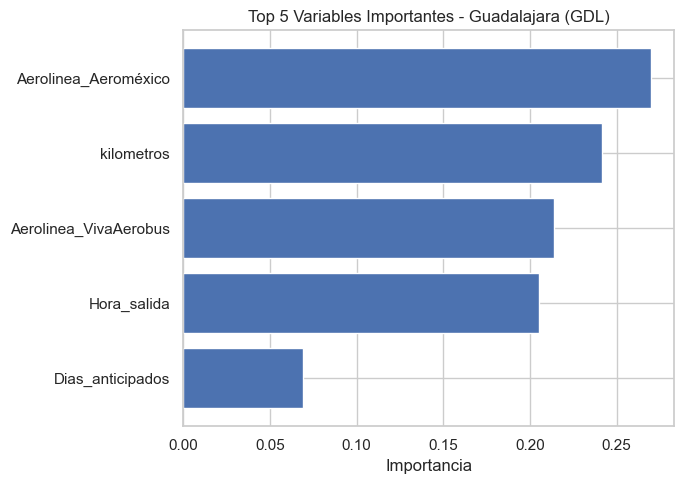

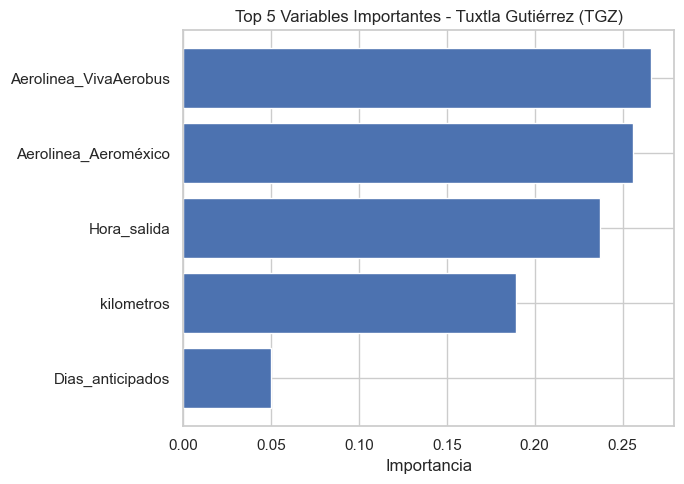

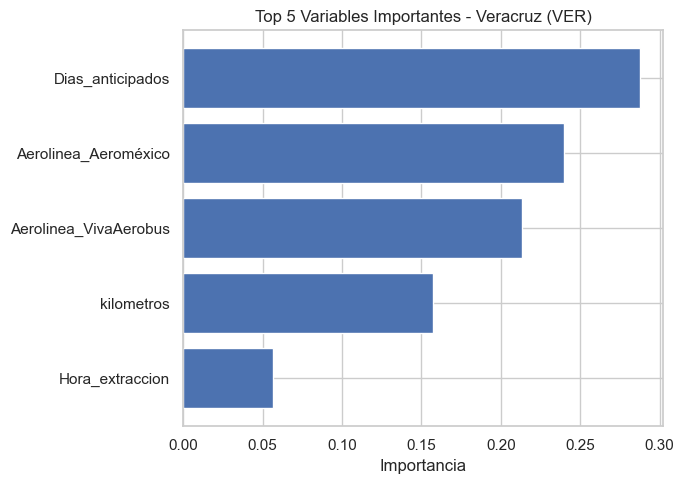

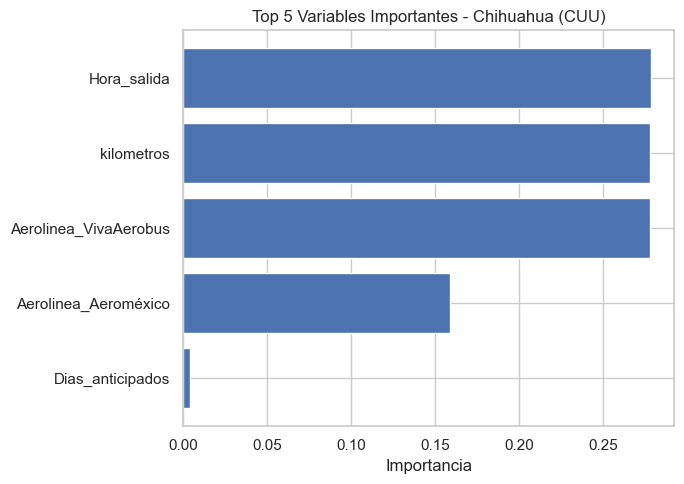

In [57]:
#Revisaremos la importancia de las variables de modelo que haya obtenido el mejor desempeño, en este caso Random Forest
#Para esto graficaremos la importancia de las variables del modelo usando matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Variables predictoras utilizadas
columnas_X = [
    'Hora_extraccion',
    'Hora_salida',
    'kilometros',
    'Dias_anticipados',
    'Aerolinea_VivaAerobus', 
    'Aerolinea_Aeroméxico'
    
]

for nombre_dest, modelo in modelos.items():

    importancias = modelo.feature_importances_
    
    # Convertir a array y ordenar top 5
    indices_top5 = np.argsort(importancias)[-5:][::-1]
    vars_top5 = [columnas_X[i] for i in indices_top5]
    imps_top5 = importancias[indices_top5]

    # Gráfica
    plt.figure(figsize=(7,5))
    plt.barh(vars_top5, imps_top5)
    plt.xlabel("Importancia")
    plt.title(f"Top 5 Variables Importantes - {nombre_dest}")
    plt.gca().invert_yaxis()  # Para que la más importante quede arriba
    plt.tight_layout()
    plt.show()


ANALISIS CON ECU. DIFERENCIAL LOGISTICA 

Para realizar un análisis más detallado, decidimos hacer una análisis más detallado sobre los datos de los precios del boleto de avión en la aerolinea Aero-México con destino a Chiapas. Decidimos utilizar una ecuación diferencial para modelar y predecir los datos.  

In [1]:
#Comenzaremos subiendo la bd a un df
import pandas as pd

df_chi = pd.read_csv('C:\\Users\\yetla\\Downloads\\filtrado_TGZ_Aeromexico.csv', encoding='latin-1')
print(df_chi.head(5))

                 Fecha_extraccion Hora_extraccion                  Origen  \
0   sábado, 11 de octubre de 2025  08:45:44 p. m.  Ciudad de México (MEX)   
1   sábado, 11 de octubre de 2025  09:03:20 p. m.  Ciudad de México (MEX)   
2   sábado, 11 de octubre de 2025  10:56:50 p. m.  Ciudad de México (MEX)   
3   sábado, 11 de octubre de 2025  11:11:07 p. m.  Ciudad de México (MEX)   
4  domingo, 12 de octubre de 2025  12:28:06 a. m.  Ciudad de México (MEX)   

                  Destino                     Fecha_salida     Hora_salida  \
0  Tuxtla Gutiérrez (TGZ)  sábado, 20 de diciembre de 2025  09:35:00 a. m.   
1  Tuxtla Gutiérrez (TGZ)  sábado, 20 de diciembre de 2026  09:35:00 a. m.   
2  Tuxtla Gutiérrez (TGZ)  sábado, 20 de diciembre de 2027  09:35:00 a. m.   
3  Tuxtla Gutiérrez (TGZ)  sábado, 20 de diciembre de 2028  09:35:00 a. m.   
4  Tuxtla Gutiérrez (TGZ)  sábado, 20 de diciembre de 2029  09:35:00 a. m.   

   Precio Sin TUA   Aerolinea kilometros Disponibilidad     Ruta  Ae

In [14]:
df_chi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Fecha_extraccion  309 non-null    object 
 1   Hora_extraccion   309 non-null    object 
 2   Origen            309 non-null    object 
 3   Destino           309 non-null    object 
 4   Fecha_salida      309 non-null    object 
 5   Hora_salida       309 non-null    object 
 6   Precio Sin TUA    309 non-null    int64  
 7   Aerolinea         309 non-null    object 
 8   kilometros        309 non-null    object 
 9   Disponibilidad    309 non-null    object 
 10  Ruta              309 non-null    object 
 11  Aerolinea.1       309 non-null    int64  
 12  Dias_anticipados  308 non-null    float64
 13  Hora_vuelo        309 non-null    float64
dtypes: float64(2), int64(2), object(10)
memory usage: 33.9+ KB


In [2]:
#Covertiremos la columna precio sin TUA a tipo numérico
df_chi['Precio Sin TUA'] = df_chi['Precio Sin TUA'].astype(float)
#Y cambiaremo el nombre de la columna Aerolinea.1
df_chi = df_chi.rename(columns={'Aerolinea.1':'Aerolinea'})

In [3]:
#Confirmaremos que no hayn colunas duplicadas y borrar las que no existen 
df_chi.columns[df_chi.columns.duplicated()]
#Borraremos las columnas duplicadas si es que existen
df_chi = df_chi.loc[:, ~df_chi.columns.duplicated()]
df_chi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Fecha_extraccion  309 non-null    object 
 1   Hora_extraccion   309 non-null    object 
 2   Origen            309 non-null    object 
 3   Destino           309 non-null    object 
 4   Fecha_salida      309 non-null    object 
 5   Hora_salida       309 non-null    object 
 6   Precio Sin TUA    309 non-null    float64
 7   Aerolinea         309 non-null    object 
 8   kilometros        309 non-null    object 
 9   Disponibilidad    309 non-null    object 
 10  Ruta              309 non-null    object 
 11  Dias_anticipados  308 non-null    float64
 12  Hora_vuelo        309 non-null    float64
dtypes: float64(3), object(10)
memory usage: 31.5+ KB


In [4]:
#eliminamos datos nulos si es que existen
df_chi = df_chi.dropna()


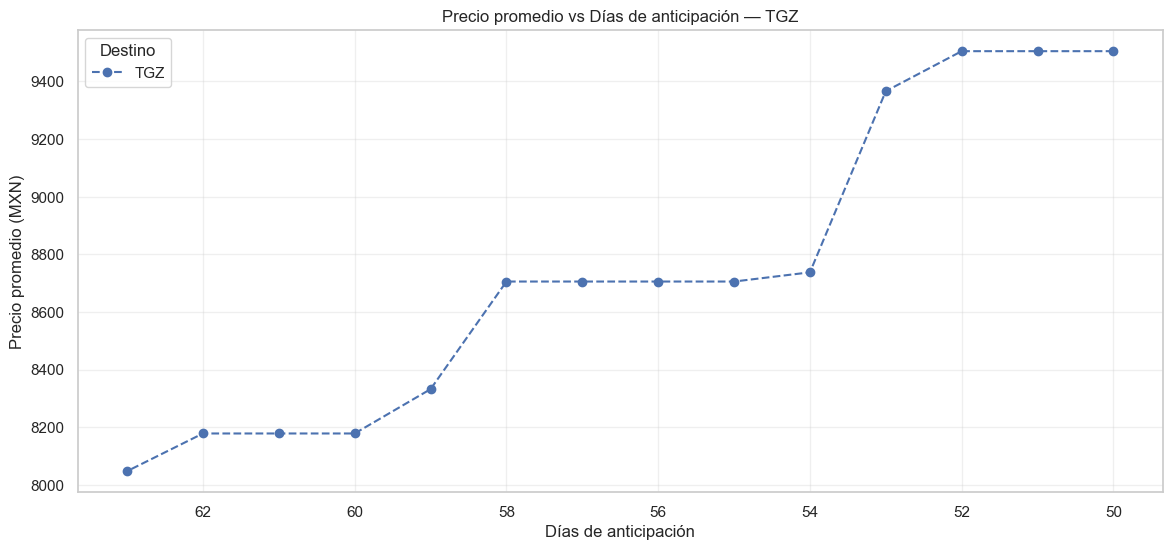

In [5]:
#En este caso, solo nos interesa los datos desde 63 días de anticipación hacia abajo, ya que desde ese día se presentan cambios 
df_chi = df_chi[df_chi['Dias_anticipados'] <= 63]
#Nueva grafica
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")
plt.figure(figsize=(14,6))
# Agrupar por destino y días de anticipación
df_group = (
    df_chi.groupby('Dias_anticipados')['Precio Sin TUA']
          .mean()
          .reset_index()
          .sort_values('Dias_anticipados')
)
# Una línea por destino
plt.plot(
    df_group['Dias_anticipados'],
    df_group['Precio Sin TUA'],
    marker='o',
    linestyle='--',
    label='TGZ'
)   
plt.title(f"Precio promedio vs Días de anticipación — TGZ")
plt.xlabel("Días de anticipación")
plt.ylabel("Precio promedio (MXN)")
plt.legend(title="Destino")
# Invertimos eje X para que se vea igual que tu ejemplo (70 → 50)
plt.gca().invert_xaxis()
plt.grid(alpha=0.3)
plt.show()


In [6]:
#Comenzaremso preparando los datos para el modelado
# 1. Filtrar días de anticipación
df_chi = df_chi[df_chi['Dias_anticipados'] <= 63]

# 2. Agrupar y calcular precio promedio por día
df_group = (
    df_chi.groupby('Dias_anticipados')["Precio Sin TUA"]
          .mean()
          .reset_index()
          .sort_values("Dias_anticipados")
)

# 3. Definir X e y usando datos agrupados
X = df_group["Dias_anticipados"].values
y = df_group["Precio Sin TUA"].values

df_group.head()


,Dias_anticipados,Precio Sin TUA
0,50.0,9505.000000
1,51.0,9505.000000
2,52.0,9505.000000
3,53.0,9366.333333
4,54.0,8737.916667


In [7]:
#Definimos la función logística en Python
import numpy as np

def logistic(t, K, r, A):
    return K / (1 + A * np.exp(-r * t))


In [8]:
#Ajustamos la ecuación logística a los datos 
from scipy.optimize import curve_fit

popt, pcov = curve_fit(logistic, X, y, 
                       p0=[10000, 0.05,5])  

K_opt, r_opt, A_opt = popt

"""

K (precio máximo esperado): techo del precio cuando se acerca la fecha.

r (velocidad del aumento): qué tan rápido suben conforme se acerca la fecha.

A (forma inicial): controla la forma de la curva al inicio.
"""
#Mostramos los parámetros optimizados
print("\n===== Parámetros ajustados =====")
print(f"K (precio máximo teórico): {K_opt:.2f} MXN")
print(f"r (tasa de incremento):    {r_opt:.4f}")
print(f"A (forma de la curva):      {A_opt:.4f}")



===== Parámetros ajustados =====
K (precio máximo teórico): 6007.04 MXN
r (tasa de incremento):    0.0310
A (forma de la curva):      -1.7769


In [9]:
#Hacemos la predicción usando el modelo ajustado
dias_future = np.linspace(min(X), max(X), 400)
predictions = logistic(dias_future, K_opt, r_opt, A_opt)


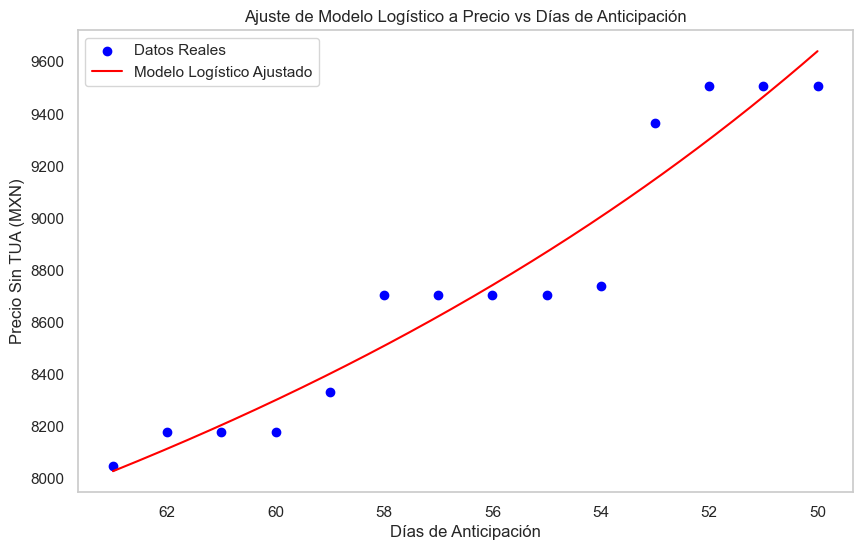

In [10]:
#Graficamos los resultados
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X, y, label='Datos Reales', color='blue')
plt.plot(dias_future, predictions, label='Modelo Logístico Ajustado', color='red')
plt.title('Ajuste de Modelo Logístico a Precio vs Días de Anticipación')
plt.xlabel('Días de Anticipación')
plt.ylabel('Precio Sin TUA (MXN)')
plt.legend()
plt.gca().invert_xaxis()
plt.grid()
plt.show()


In [17]:
#Ahora crearemos una tabla comparativa entre los precios reales y los predichos por el modelo
import pandas as pd
df_comparativa = pd.DataFrame({
    'Dias_anticipados': X,
    'Precio_Real': y,
    'Precio_Predicho': logistic(X, K_opt, r_opt, A_opt)
})
df_comparativa.head()
#y después exportaremos la tabla a un archivo de Excel
#df_comparativa.to_excel('C:\\Users\\yetla\\Downloads\\comparativa_precios_TGZ_Aeromexico.xlsx', index=False)


,Dias_anticipados,Precio_Real,Precio_Predicho
0,50.0,9505.000000,9640.521745
1,51.0,9505.000000,9465.678015
2,52.0,9505.000000,9302.123480
3,53.0,9366.333333,9148.870370
4,54.0,8737.916667,9005.042214


In [14]:
#Mediremos el desempeño del modelo logístico ajustado
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ================================
# 1. Predicciones del modelo
# ================================
y_pred = logistic(X, K_opt, r_opt, A_opt)

# ================================
# 2. MAE (Error Absoluto Medio)
# ================================
mae = mean_absolute_error(y, y_pred)

# ================================
# 3. MSE (Error Cuadrático Medio)
# ================================
mse = mean_squared_error(y, y_pred)

# ================================
# 4. RMSE (Raíz del MSE)
# ================================
rmse = np.sqrt(mse)

# ================================
# 5. R² (Coeficiente de determinación)
# ================================
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r2 = 1 - (ss_res / ss_tot)

# ================================
# 6. MAPE (Error Porcentual Medio)
# ================================
mape = np.mean(np.abs((y - y_pred) / y)) * 100

# ================================
# 7. Mostrar resultados
# ================================
print("Métricas del Modelo Logístico")
print("---------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")
print(f"MAPE : {mape:.2f}%")


Métricas del Modelo Logístico
---------------------------------
MAE  : 117.4935
MSE  : 19894.0348
RMSE : 141.0462
R²   : 0.9256
MAPE : 1.33%


El desempeño del modelo logístico se evaluó mediante un conjunto de métricas que ayudan a comprender qué tan bien logra predecir el comportamiento del precio en función de los días de anticipación. El MAE, con un valor de 117.49, indica que el modelo presenta un error promedio de aproximadamente 117 pesos por predicción, mostrando una desviación moderada entre los valores reales y los estimados. El MSE, igual a 19,894.03, refleja el promedio de los errores al cuadrado, penalizando de manera más fuerte los errores grandes; mientras que su raíz, el RMSE, fue de 141.05, lo que sugiere que la desviación típica de las predicciones frente a los valores reales ronda los 141 pesos. Por otro lado, el coeficiente de determinación R² alcanzó un valor de 0.9256, lo cual indica que el modelo logra explicar el 92.56% de la variabilidad observada en los precios, representando un ajuste sólido y consistente con la estructura de los datos. Finalmente, el MAPE fue de 1.33%, un error porcentual extremadamente bajo que confirma que, en relación con el valor real, las predicciones son altamente precisas. En conjunto, estos resultados muestran que el modelo logístico ofrece un excelente rendimiento y capta adecuadamente la dinámica del precio respecto a los días de anticipación.


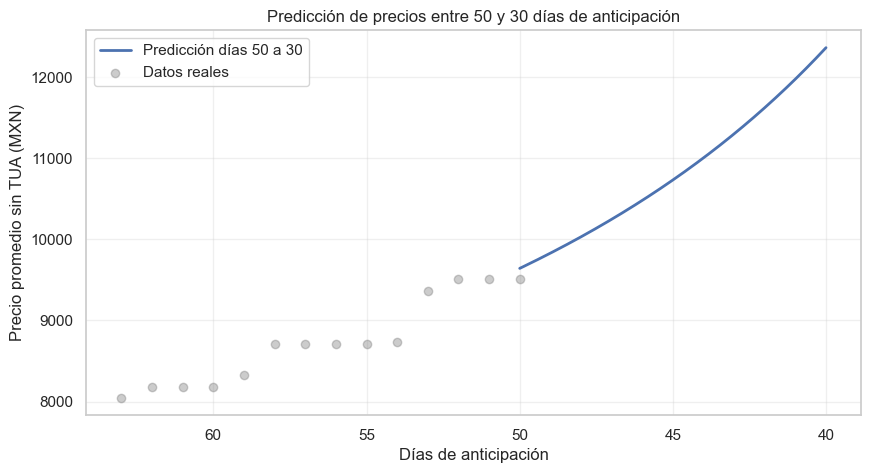

In [15]:
# Crear rango de días entre 50 y 30
dias_50_30 = np.linspace(40, 50, 400)

# Predicción para ese rango
pred_50_30 = logistic(dias_50_30, K_opt, r_opt, A_opt)

# ===========================
# GRAFICAR PREDICCIÓN 50 → 30
# ===========================

plt.figure(figsize=(10,5))

plt.plot(dias_50_30, pred_50_30, linewidth=2, label="Predicción días 50 a 30")
plt.scatter(X, y, color="gray", alpha=0.4, label="Datos reales")  # opcional

plt.title("Predicción de precios entre 50 y 30 días de anticipación")
plt.xlabel("Días de anticipación")
plt.ylabel("Precio promedio sin TUA (MXN)")
plt.grid(True, alpha=0.3)
plt.gca().invert_xaxis()
plt.legend()
plt.show()


In [16]:
#Ahora paseremos los datos de esta grafica en una tabla de Excel
import pandas as pd
df_50_30 = pd.DataFrame({
    'Dias_anticipados': dias_50_30,
    'Precio_Predicho': pred_50_30
})
df_50_30.to_excel('C:\\Users\\yetla\\Downloads\\prediccion_50_30_TGZ_Aeromexico.xlsx', index=False)


A partir del análisis de los precios sin TUA y los días de anticipación, observamos que los algoritmos de las aerolíneas ajustan los precios siguiendo patrones que no siempre son transparentes para los usuarios. Aunque a primera vista estos modelos buscan maximizar ganancias en función de la demanda, en la práctica pueden generar discriminación algorítmica, ya que afectan de forma desigual a distintos grupos sociales. Por ejemplo, las personas con menor capacidad económica tienden a comprar vuelos con menos anticipación y, según los modelos predictivos que analizamos, esos días concentran los precios más altos. De esta manera, un algoritmo que parece neutral en realidad reproduce desigualdades sociales, ya que penaliza a quienes no pueden pagar con anticipación o no tienen flexibilidad en sus fechas.                                           



Los algoritmos no discriminan por intención, pero sí por efecto: al aumentar los precios conforme se acerca la fecha del vuelo, terminan afectando más a quienes tienen menos recursos o menos flexibilidad de tiempo. Nuestro modelo muestra cómo esta estructura de precios puede traducirse en una forma de discriminación algorítmica y social